# 2. Исследовательский анализ (EDA)

Смотрим на очищенные данные: статистика, выбросы, графики. Цель — понять, какие признаки связаны с возвратом.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # чтобы работал импорт из папки src

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data, features

sns.set_theme(style="whitegrid")

In [2]:
clean = data.clean(data.load_raw())
average = clean["readmit_30"].mean() * 100
print(clean.shape, "— доля возвратов", round(average, 1), "%")

(99340, 44) — доля возвратов 11.4 %


## Описательная статистика

In [3]:
clean[features.NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,99340.0,4.38,2.97,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,99340.0,42.91,19.61,1.0,31.0,44.0,57.0,132.0
num_procedures,99340.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,99340.0,15.98,8.09,1.0,10.0,15.0,20.0,81.0
number_outpatient,99340.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,99340.0,0.20,0.94,0.0,0.0,0.0,0.0,76.0
number_inpatient,99340.0,0.63,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,99340.0,7.40,1.94,1.0,6.0,8.0,9.0,16.0
total_prior_visits,99340.0,1.20,2.29,0.0,0.0,0.0,2.0,80.0
age_num,99340.0,65.74,15.95,5.0,55.0,65.0,75.0,95.0


## Выбросы

Правило IQR: выброс — значение дальше 1,5 × IQR от первого или третьего квартиля. IQR — разница между ними.

Выбросы считаем, но не удаляем: это настоящие пациенты с большим числом визитов.

In [4]:
rows = []
for col in features.NUMERIC:
    q1, q3 = clean[col].quantile(0.25), clean[col].quantile(0.75)
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    share = ((clean[col] < low) | (clean[col] > high)).mean() * 100
    rows.append({"признак": col, "нижняя граница": low, "верхняя граница": high, "выбросов, %": round(share, 2)})
pd.DataFrame(rows)

,признак,нижняя граница,верхняя граница,"выбросов, %"
0,time_in_hospital,-4.0,12.0,2.16
1,num_lab_procedures,-8.0,96.0,0.12
2,num_procedures,-3.0,5.0,4.83
3,num_medications,-5.0,35.0,2.47
4,number_outpatient,0.0,0.0,16.46
5,number_emergency,0.0,0.0,11.17
6,number_inpatient,-1.5,2.5,6.86
7,number_diagnoses,1.5,13.5,0.28
8,total_prior_visits,-3.0,5.0,4.35
9,age_num,25.0,105.0,0.86


## Баланс классов

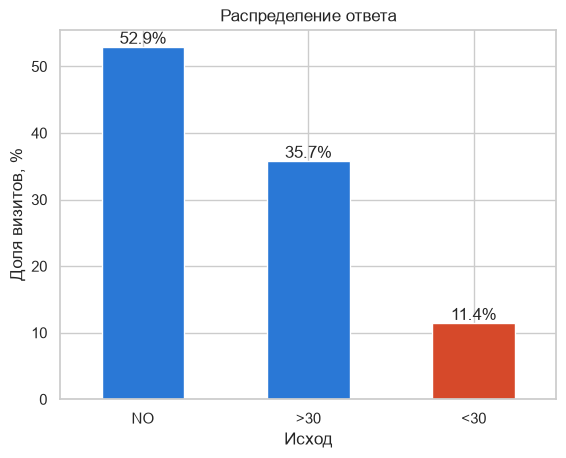

In [5]:
share = clean["readmitted"].value_counts(normalize=True).reindex(["NO", ">30", "<30"]) * 100
ax = share.plot.bar(color=["#2a78d6", "#2a78d6", "#d6492a"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set(xlabel="Исход", ylabel="Доля визитов, %", title="Распределение ответа");

Раньше 30 дней возвращаются 11,4%. Поэтому accuracy не подходит: ответ «никто не вернётся» был бы верен в 89% случаев.

## Прошлые госпитализации

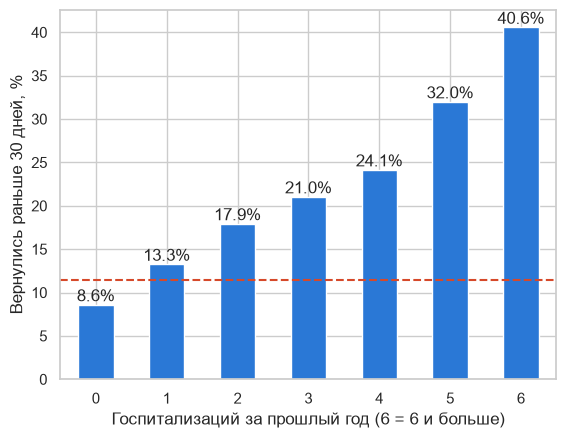

In [6]:
rate = clean.groupby(clean["number_inpatient"].clip(upper=6))["readmit_30"].mean() * 100
ax = rate.plot.bar(color="#2a78d6", rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.axhline(average, color="#d6492a", linestyle="--")
ax.set(xlabel="Госпитализаций за прошлый год (6 = 6 и больше)", ylabel="Вернулись раньше 30 дней, %");

Самая сильная зависимость: от 8,6% без госпитализаций до 40,6% при шести и более.

## Группа основного диагноза

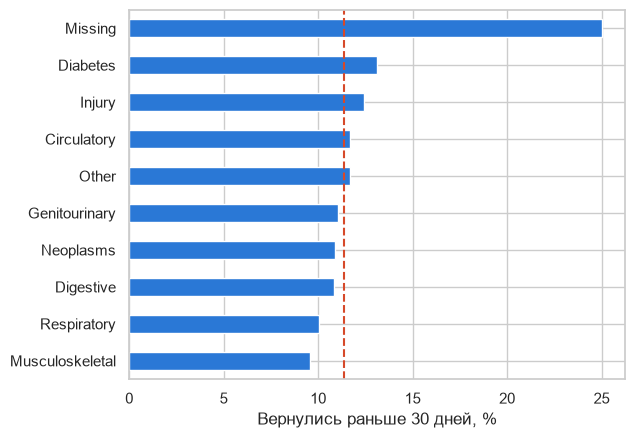

In [7]:
rate = clean.groupby("diag_1_group")["readmit_30"].mean().sort_values() * 100
ax = rate.plot.barh(color="#2a78d6")
ax.axvline(average, color="#d6492a", linestyle="--")
ax.set(xlabel="Вернулись раньше 30 дней, %", ylabel="");

Группы различаются слабо: от 9,5% до 13,1%. В группе `Missing` всего 20 визитов.

## Числовые признаки у вернувшихся и не вернувшихся

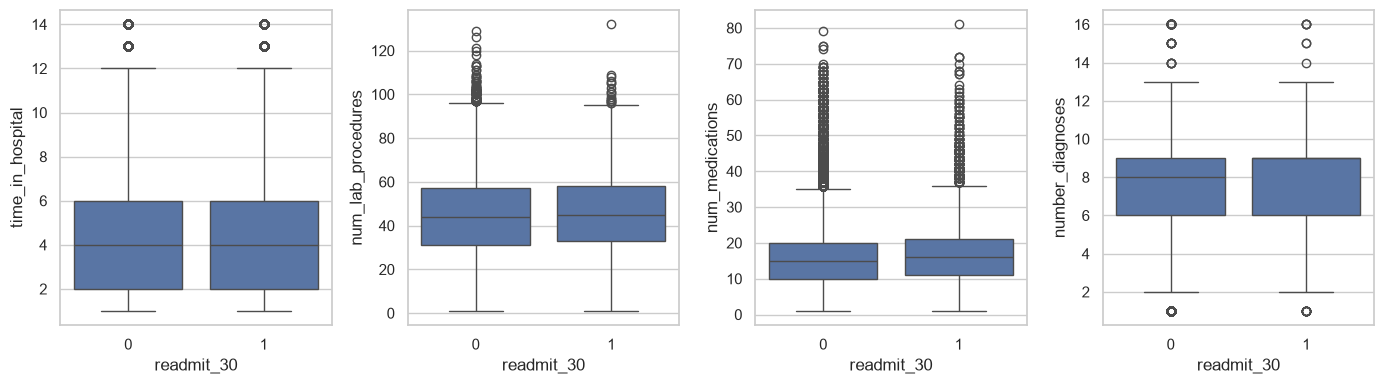

In [8]:
columns = ["time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, columns):
    sns.boxplot(data=clean, x="readmit_30", y=col, ax=ax)
fig.tight_layout()

Распределения почти совпадают: по одному такому признаку группы не различить.

## Корреляция

Корреляция Спирмена показывает, растут ли два признака вместе. Она считается по рангам, поэтому не чувствительна к выбросам.

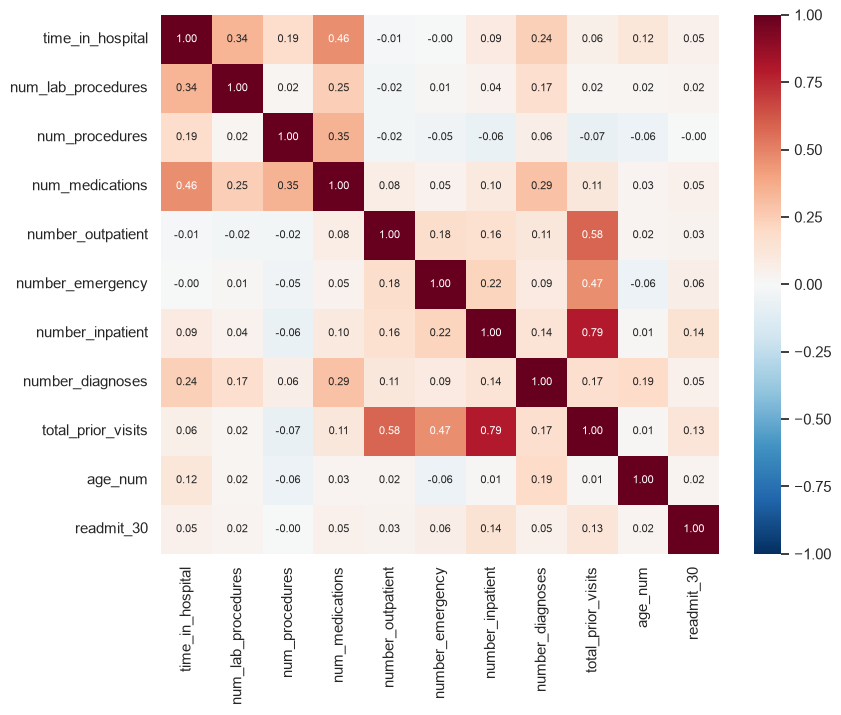

In [9]:
corr = clean[features.NUMERIC + ["readmit_30"]].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8});

In [10]:
corr["readmit_30"].drop("readmit_30").sort_values(ascending=False).round(3)

number_inpatient      0.141
total_prior_visits    0.126
number_emergency      0.064
time_in_hospital      0.053
number_diagnoses      0.052
num_medications       0.048
number_outpatient     0.035
age_num               0.024
num_lab_procedures    0.024
num_procedures       -0.005
Name: readmit_30, dtype: float64

Связи с ответом слабые. Сильнее всего — `number_inpatient` (0,14).

## Визиты одного пациента

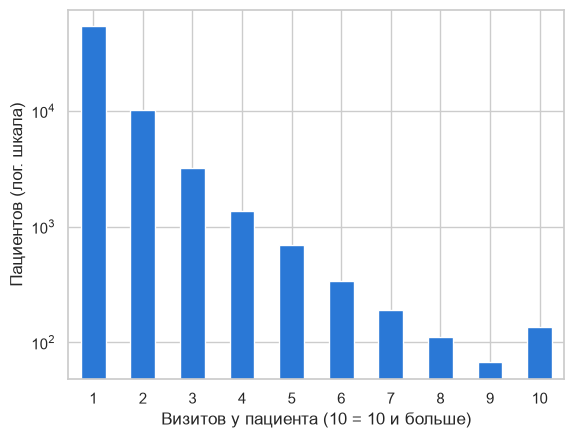

In [11]:
visits = clean["patient_nbr"].value_counts()
ax = visits.clip(upper=10).value_counts().sort_index().plot.bar(color="#2a78d6", rot=0, logy=True)
ax.set(xlabel="Визитов у пациента (10 = 10 и больше)", ylabel="Пациентов (лог. шкала)");

In [12]:
print("Пациентов:", len(visits))
print("С несколькими визитами:", (visits > 1).sum(), f"({(visits > 1).mean() * 100:.1f}%)")

Пациентов: 69987
С несколькими визитами: 16341 (23.3%)


У 23% пациентов несколько визитов. Поэтому делить данные на train и test нужно по пациентам.

## Выводы

- Классы несбалансированы: 11,4% возвратов.
- Главный признак — число прошлых госпитализаций.
- Остальные признаки связаны с ответом слабо, высокой точности ждать не стоит.
- Выбросы — настоящие пациенты высокого риска, их не удаляем.